# Aliasing

### MPATE-GE 2598 Fundamentals of Digital Signal Theory Lab

In [1]:
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio

## Complex Waveforms

Write a function that generates the values of a square wave. It should take in the number of overtones, the fundamental frequency, the sampling rate, and the duration. Then, it should return the signal and its time vector.

The formula for a square wave is:
$x(t) = \sum_{k=1}^{k_{max}}[\frac{1}{k} \cdot \sin(k \cdot 2\pi f_0 \cdot t)]$ where $k$ is odd.

$k=1$ represents no overtones, only the $f_0$.

In [2]:
def squarewave(n, f0, fs, duration):
    """Generate a square wave.
    """
    # get time vector
    num_samples = fs * duration
    t = np.linspace(0, duration, num=num_samples)

    # make placeholder array
    x = np.zeros(num_samples)

    # n = 0, k = 1
    # n = 1, k = 1, 3
    # n = 2, k = 1, 3, 5
    # ... k_max = 2 * n + 1
    for k in range(1, 2 * n + 2, 2):  # + 1 for exclusive stop
        # x = x + ...
        x += (1/k) * np.sin(k * 2 * np.pi * f0 * t)
        
    return x, t

### Sine Wave

Now, using the function you wrote above, generate a **sine** wave with a frequency of 98 Hz, and a duration of 1 second. Use a sampling rate of 48 kHz.

In [3]:
n = 0  # sine wave -> no overtones
f0 = 98
fs = 48000
duration = 1

In [4]:
x, time_vector = squarewave(n, f0, fs, duration)

Play the generated signal.

In [5]:
Audio(x, rate=fs)

Now, plot the signal for 6 _periods_.

In [6]:
T = 1/f0  # time to complete one cycle of wave in seconds

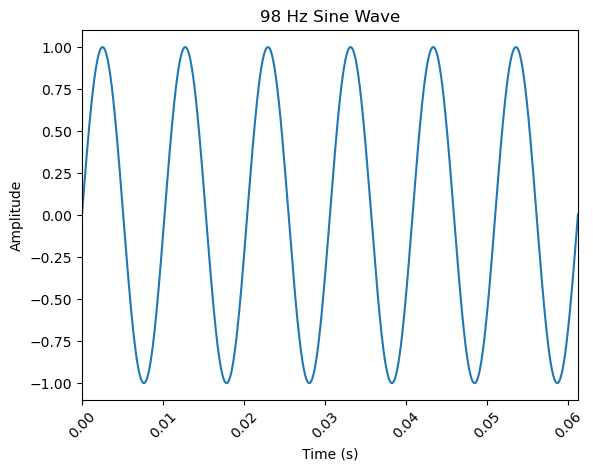

In [7]:
plt.plot(time_vector, x)
plt.xlim(0, 6 * T)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"{f0} Hz Sine Wave")
plt.xticks(rotation=45)
plt.show()

Plot the spectrogram.

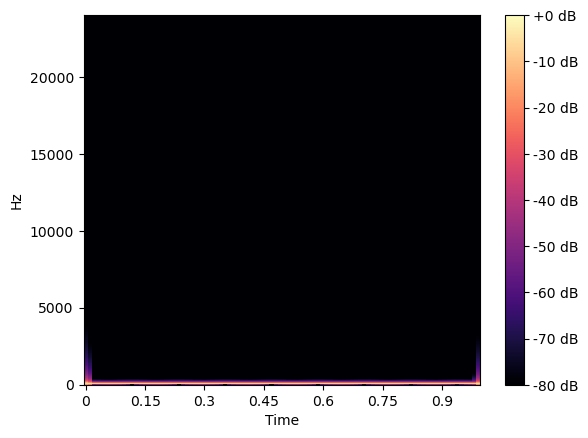

In [8]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=fs)
plt.colorbar(img, format="%+2.f dB")
plt.show()

### Square Wave

Generate a square wave with 10 overtones, using the same parameters as above.

In [9]:
n = 10
f0 = 98
fs = 48000
duration = 1

In [10]:
x, time_vector = squarewave(n, f0, fs, duration)

Play the generated signal.

In [11]:
Audio(x, rate=fs)

Now, plot the signal for 6 _periods_.

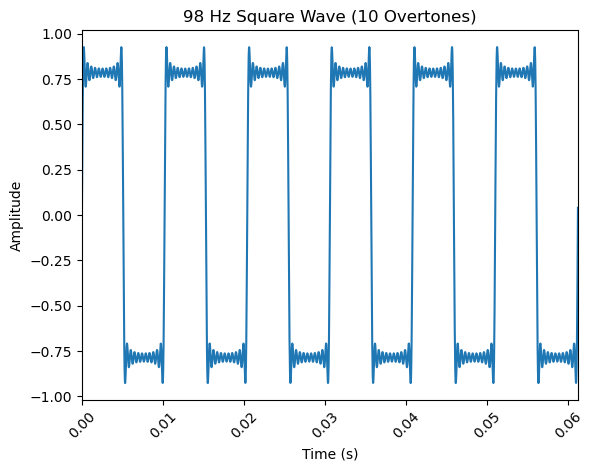

In [12]:
plt.plot(time_vector, x)
plt.xlim(0, 6 * T)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"{f0} Hz Square Wave ({n} Overtones)")
plt.xticks(rotation=45)
plt.show()

Let's plot the spectrogram. What do you see?

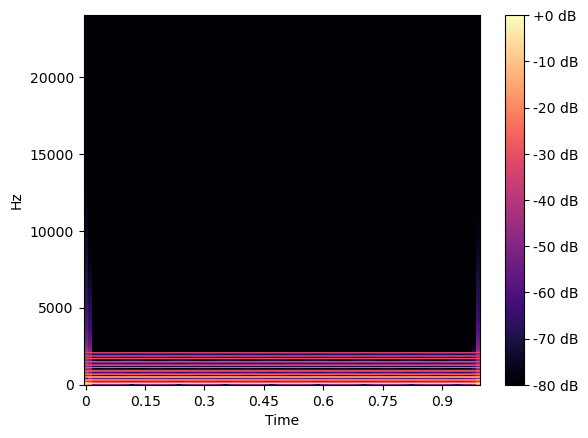

In [13]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=fs)
plt.colorbar(img, format="%+2.f dB")
plt.show()

This time, generate a square wave with 200 overtones. Keep the other parameters the same.

In [14]:
n = 200
f0 = 98
fs = 48000
duration = 1

In [15]:
x, time_vector = squarewave(n, f0, fs, duration)

In [16]:
Audio(x, rate=fs)

Now, plot the signal for 6 _periods_.

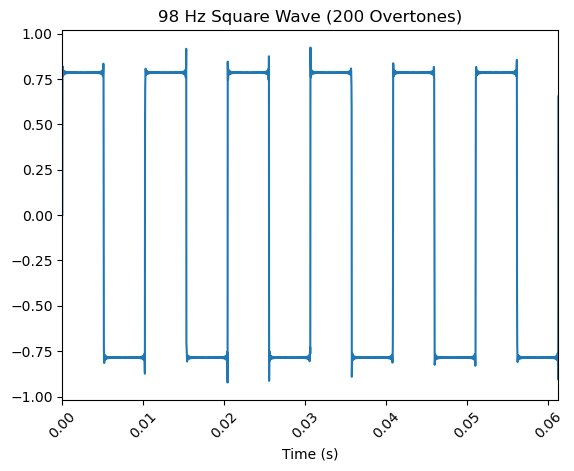

In [17]:
plt.plot(time_vector, x)
plt.xlim(0, 6 * T)
plt.xlabel("Time (s)")
plt.title(f"{f0} Hz Square Wave ({n} Overtones)")
plt.xticks(rotation=45)
plt.show()

Let's plot the spectrogram. What do you see?

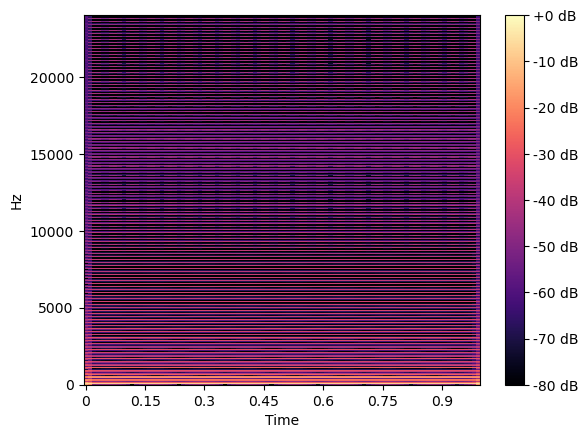

In [18]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=fs)
plt.colorbar(img, format="%+2.f dB")
plt.show()

What is the frequency of the highest overtone? What is the Nyquist frequency?

In [19]:
print(f"The Nyquist frequency is {fs/2} Hz")
print(f"The frequency of the highest overtone is {(2 * n + 1) * f0} Hz")

The Nyquist frequency is 24000.0 Hz
The frequency of the highest overtone is 39298 Hz


How would you change your function to prevent aliasing? You do not need to implement this now, but think about it...

## More on Aliasing and Sample Rates

I have been lying to you. `librosa` does indeed have a function that loads audio into Python. However, I have been telling you to use `soundfile`. Why?

Hint: Look at the [librosa documentation](https://librosa.org/doc/latest/api/generated/librosa.load.html#librosa.load).

Try loading in an audio file with the `librosa` function.

In [20]:
y, sr = librosa.load('bark_howl.wav', sr=None)
print(f"The sample rate is {sr} Hz.")

The sample rate is 44100 Hz.


For more information on why `librosa` does this, read [this blog post](https://librosa.org/blog/2019/07/17/resample-on-load/).

To drive the importance of sample rates home, let's take a look at a sine sweep with an exaggerated sample rate.

In [21]:
min_freq = 1000
max_freq = 12000
fs = 8000
dur = 5

x = librosa.chirp(fmin=min_freq, fmax=max_freq, sr=fs, duration=dur)

Play back the audio at $f_s$.

In [22]:
Audio(x, rate=fs)

Plot the spectrogram. What is happening?

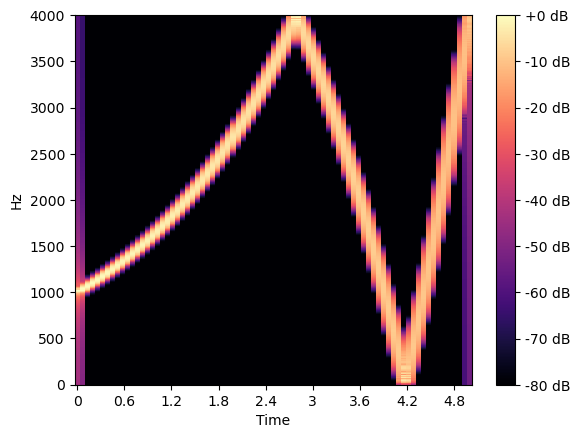

In [23]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=fs)
plt.colorbar(img, format="%+2.f dB")
plt.show()

## White Noise Generator

White noise is a random signal having equal intensity at different frequencies ([source](https://en.wikipedia.org/wiki/White_noise)).

Write a function that generates noise for a specified duration, at a given sample rate. It should normalize the signal to be between -1 and +1.

In [24]:
def noise(fs, duration):
    """Generate random noise.
    """
    num_samples = fs * duration
    time_vector = np.linspace(0, duration, num=num_samples)

    y = np.random.randn(num_samples)

    y = y / np.max(np.abs(y))

    return y, time_vector

Generate noise at a sample rate of 44.1kHz for 3 seconds.

In [25]:
fs = 44100
duration = 3

y, time_vector = noise(fs, duration)

Play the signal.

In [26]:
Audio(y, rate=fs)

Plot the signal's waveform and spectrogram.

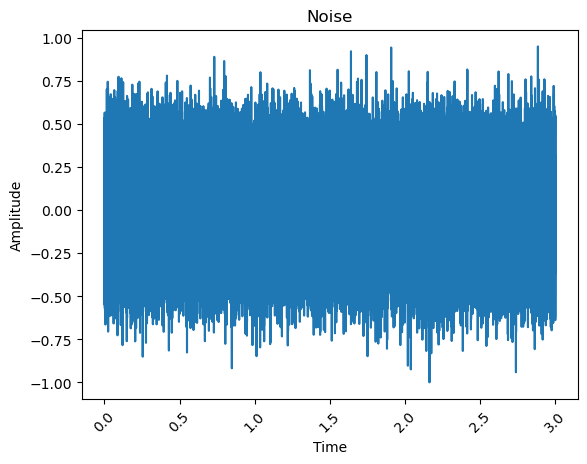

In [27]:
plt.plot(time_vector, y)
plt.title("Noise")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.xticks(rotation=45)
plt.show()

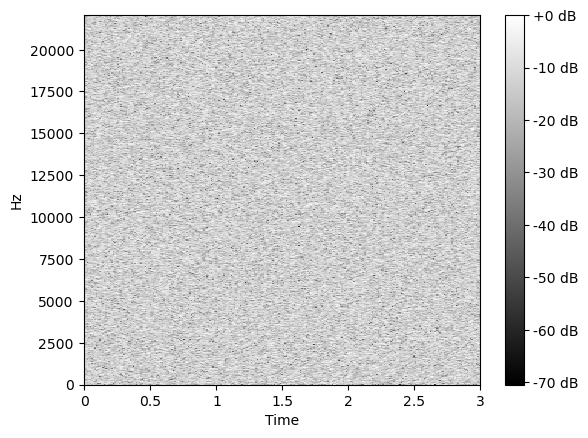

In [28]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=fs, cmap='gray')
plt.colorbar(img, format="%+2.f dB")
plt.show()

***
_End of Class 5_